Lecture des fichiers csv foourinis

In [1]:
import pandas as pd

# Charger le fichier CSV dans un DataFrame
df1 = pd.read_csv('../data/winequality-red.csv', sep=';')
df2 = pd.read_csv('../data/winequality-white.csv', sep=';')
# Afficher les 5 premières lignes
print(df1.head())
print(df2.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [2]:
df1["Type"] = "red"
df2["Type"] = "white"


Ajout d'un colone type puis fusion des 2 datasets

In [3]:
# 2. Concaténer les DataFrames verticalement
df_combine = pd.concat([df1, df2], ignore_index=True)

# 3. Sauvegarder dans un nouveau fichier CSV
df_combine.to_csv('../data/winequality.csv', index=False)

In [4]:
df = pd.read_csv('../data/winequality.csv', sep=',')
df.shape 
df.head() 
df.info() 
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  Type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


Detection des duplicats et supressions

In [5]:
print(df.duplicated().sum())

1177


In [6]:
df = df.drop_duplicates()
df.shape

(5320, 13)

Valeurs abhérantes

In [7]:
# Les 11 variables physico-chimiques (on exclut Type = texte, et quality = la cible)
cols = df.select_dtypes("number").columns.drop("quality")

resultats = []
for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1                        # écart interquartile
    borne_basse = q1 - 1.5 * iqr
    borne_haute = q3 + 1.5 * iqr

    # True pour chaque valeur hors des bornes, puis on compte les True
    est_outlier = (df[col] < borne_basse) | (df[col] > borne_haute)
    n_outliers = est_outlier.sum()
    pct = 100 * n_outliers / len(df)

    resultats.append({"variable": col, "n_outliers": n_outliers, "pourcentage": round(pct, 2)})

# Un tableau trié du plus touché au moins touché
outliers = pd.DataFrame(resultats).sort_values("pourcentage", ascending=False)
outliers

,variable,n_outliers,pourcentage
0,fixed acidity,304,5.71
1,volatile acidity,279,5.24
4,chlorides,237,4.45
9,sulphates,163,3.06
2,citric acid,143,2.69
3,residual sugar,141,2.65
8,pH,49,0.92
5,free sulfur dioxide,44,0.83
6,total sulfur dioxide,10,0.19
7,density,3,0.06


In [8]:
au_moins_un = pd.Series(False, index=df.index)   # au départ, aucune ligne n'est marquée

for col in cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    est_outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    au_moins_un = au_moins_un | est_outlier       # une ligne reste marquée dès qu'elle a été outlier une fois

n = au_moins_un.sum()
print(f"{n} lignes ont au moins un outlier, soit {100 * n / len(df):.1f} % des données")

1094 lignes ont au moins un outlier, soit 20.6 % des données


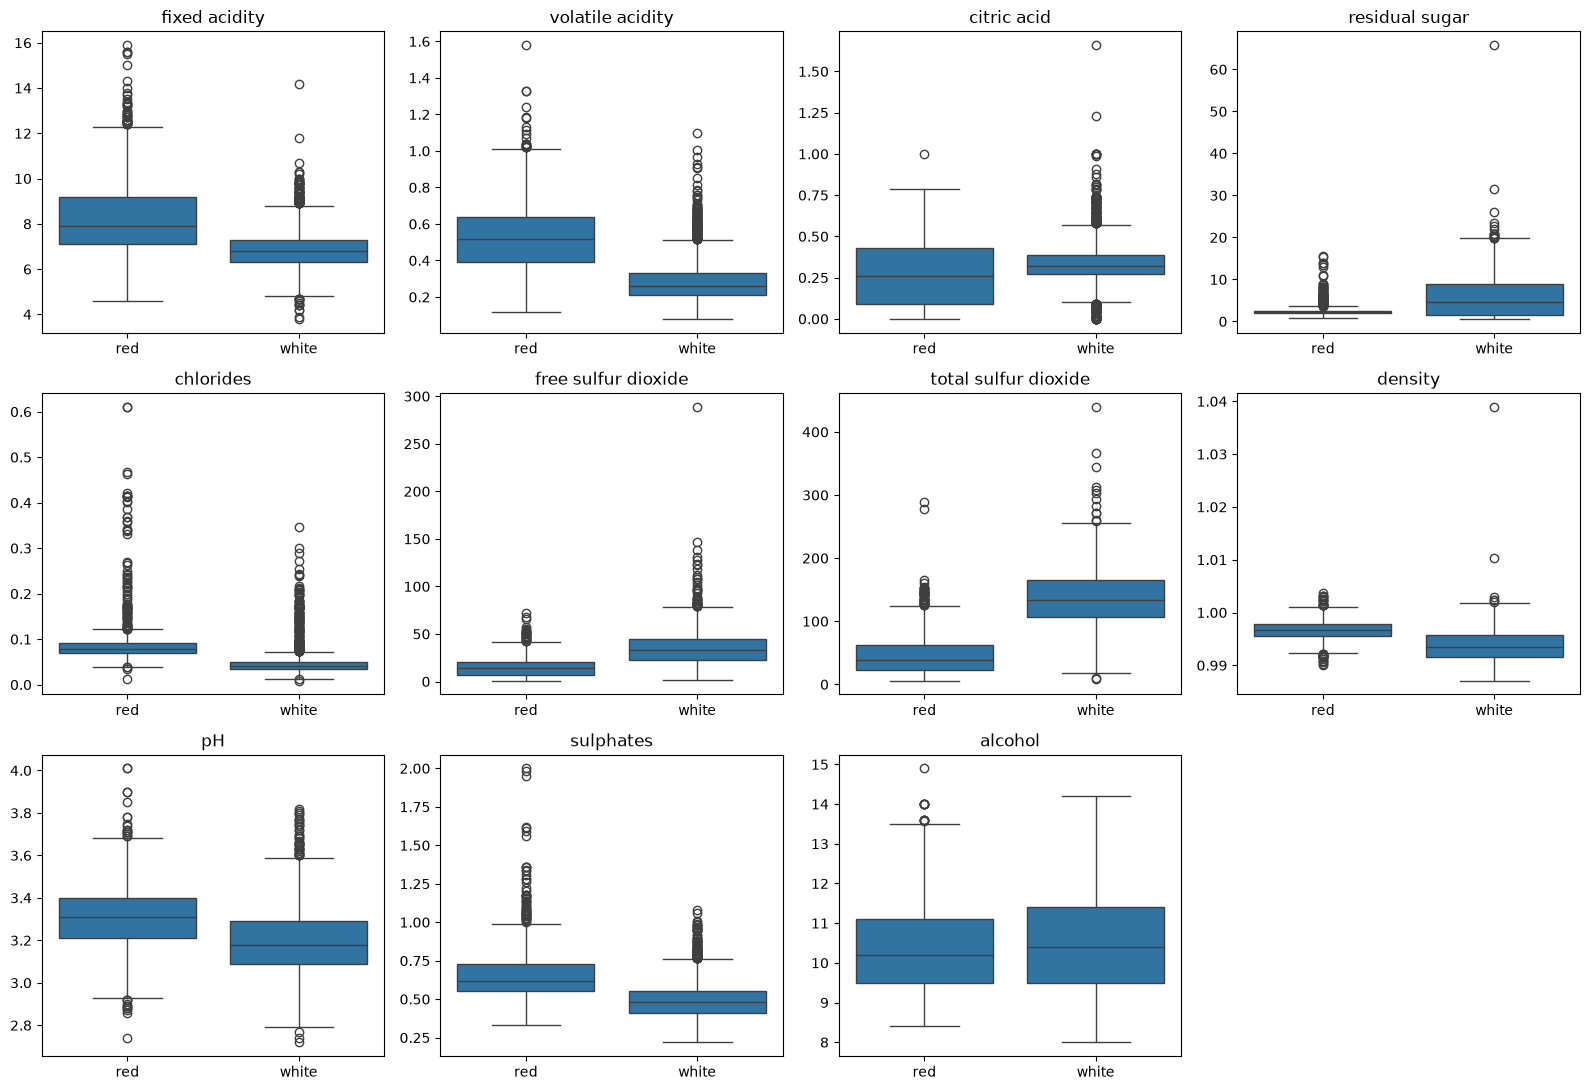

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 4, figsize=(16, 11))   # grille de 12 cases pour 11 variables
for ax, col in zip(axes.flat, cols):
    sns.boxplot(data=df, x="Type", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[-1].axis("off")                           # on masque la 12e case, vide
plt.tight_layout()
plt.show()

In [10]:
def compter_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

comparaison = pd.DataFrame({
    "bornes globales": [compter_outliers(df[c]) for c in cols],
    "bornes par type": [df.groupby("Type")[c].apply(compter_outliers).sum() for c in cols],
}, index=cols)
comparaison

,bornes globales,bornes par type
fixed acidity,304,147
volatile acidity,279,152
citric acid,143,224
residual sugar,141,142
chlorides,237,265
free sulfur dioxide,44,70
total sulfur dioxide,10,59
density,3,41
pH,49,74
sulphates,163,151


Encodage de `Type` et création de la cible binaire

In [11]:
df["Type_encoded"] = df["Type"].map({"red": 0, "white": 1})

# quality >= 7, sinon 0
df["quality_binary"] = (df["quality"] >= 7).astype(int)

## Analyse exploratoire : distributions, boxplots, corrélations

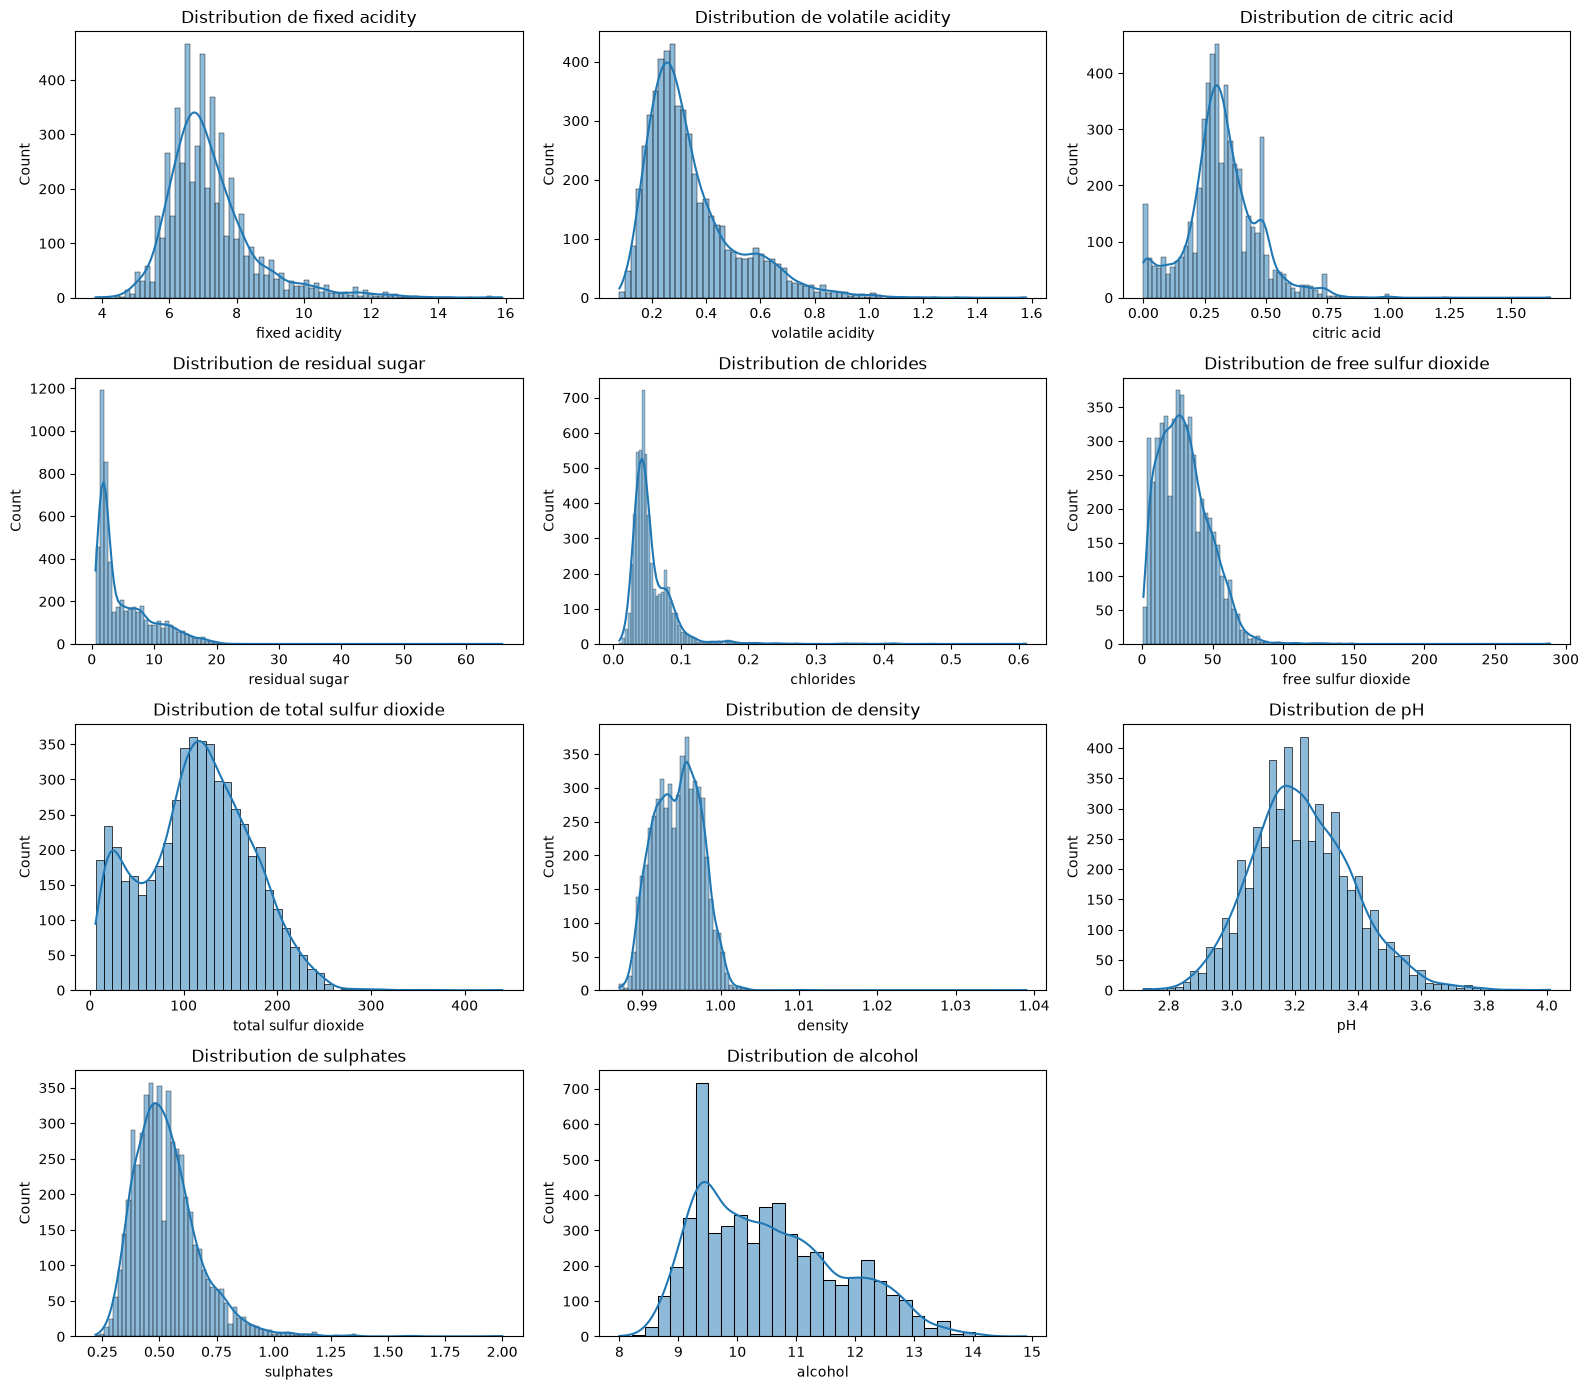

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distributions des variables physico-chimiques
variables = [
    col for col in df.select_dtypes(include="number").columns
    if col not in ("quality", "Type_encoded", "quality_binary")
]

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.flat, variables):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution de {col}")
for ax in axes.flat[len(variables):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Correlation

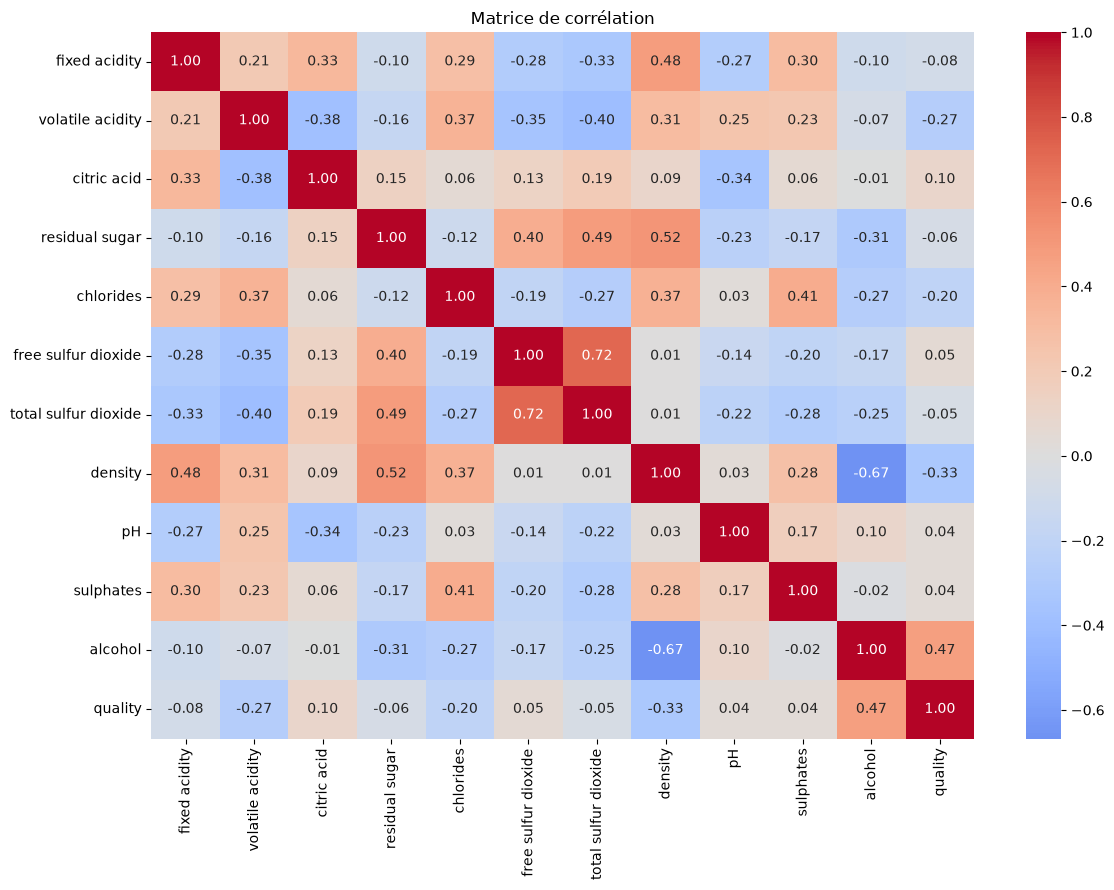

In [13]:
correlations = df[variables + ["quality"]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

Séparation des données

In [14]:
features = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
    "pH", "sulphates", "alcohol", "Type_encoded",
]
X = df[features]
y = df["quality_binary"]
print(X.shape, y.shape)   # (5320, 12) (5320,)

(5320, 12) (5320,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20 % pour le test
    stratify=y,         # garde la même proportion de bons vins dans train et test
    random_state=42,    # même découpage à chaque exécution, et pour toute l'équipe
)

In [16]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(X_train, y_train, random_state=42)

In [17]:
print("train :", y_train.mean())
print("test  :", y_test.mean())

train : 0.18961466165413535
test  : 0.18984962406015038


In [20]:
import pandas as pd

scores = pd.DataFrame({
    "info_mutuelle": mi,
    "corr_cible": X_train.corrwith(y_train),
}, index=X_train.columns)

scores.sort_values("info_mutuelle", ascending=False)

,info_mutuelle,corr_cible
alcohol,0.098042,0.422594
density,0.057565,-0.297680
chlorides,0.031540,-0.158681
total sulfur dioxide,0.028952,-0.074100
volatile acidity,0.027927,-0.142750
citric acid,0.021087,0.058113
free sulfur dioxide,0.014326,0.005473
residual sugar,0.010195,-0.085749
sulphates,0.008896,0.038398
pH,0.008286,0.041527


In [19]:
discrete = [col == "Type_encoded" for col in X_train.columns]
mi = mutual_info_classif(X_train, y_train, discrete_features=discrete, random_state=42)

Ça a marché : Type_encoded a maintenant un score non nul (0,0034). Il reste faible, ce qui confirme que le type de vin, pris seul, renseigne peu sur la qualité.

Compare avec ton tableau précédent : le haut du classement n’a pas bougé (alcohol, density, chlorides), mais le bas a changé. free sulfur dioxide était dernier avec 0,005, il est maintenant 7ᵉ avec 0,014. total sulfur dioxide est passé devant volatile acidity. C’est exactement le point 4 de mon dernier message : pour les petites valeurs, l’information mutuelle est une estimation bruitée. Le haut du classement est fiable, l’ordre du bas ne l’est pas. Ça fait une bonne phrase pour ton commentaire.

Attention à l’ordre des cellules, encore une fois. Ta nouvelle cellule mi ([19]) est placée sous le tableau ([20]). Au prochain Run All, le tableau sera calculé avant elle, donc avec l’ancien mi. Le mieux : modifie directement l’ancienne cellule mi (celle au-dessus du tableau) en y ajoutant discrete_features=discrete, puis supprime celle du dessous. Règle générale : quand tu corriges un calcul, modifie la cellule existante plutôt que d’en ajouter une nouvelle plus bas.

methode wrapper RFECV

In [21]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

modele = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
)

rfecv = RFECV(
    modele,
    step=1,                     # on retire une variable à chaque tour
    cv=5,                       # validation croisée 5-fold (cours, séance 1)
    scoring="f1",               # le F1, adapté aux classes déséquilibrées
    importance_getter="named_steps.logisticregression.coef_",
)
rfecv.fit(X_train, y_train)

print("Nombre de variables retenues :", rfecv.n_features_)
print("Retenues :", list(X_train.columns[rfecv.support_]))
print("Éliminées :", list(X_train.columns[~rfecv.support_]))

Nombre de variables retenues : 11
Retenues : ['fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'Type_encoded']
Éliminées : ['citric acid']


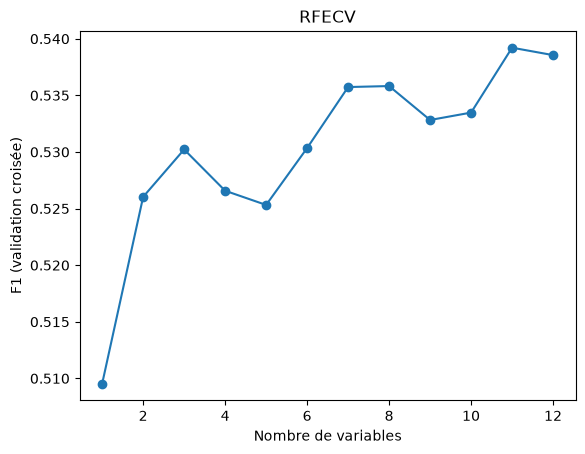

In [22]:
import matplotlib.pyplot as plt

scores_cv = rfecv.cv_results_["mean_test_score"]
plt.plot(range(1, len(scores_cv) + 1), scores_cv, marker="o")
plt.xlabel("Nombre de variables")
plt.ylabel("F1 (validation croisée)")
plt.title("RFECV")
plt.show()

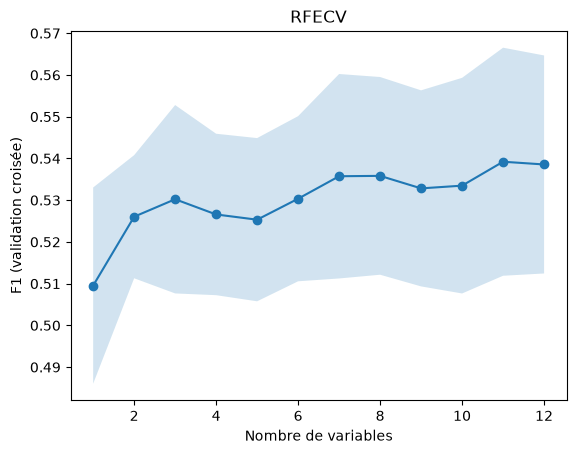

In [23]:
moy = rfecv.cv_results_["mean_test_score"]
std = rfecv.cv_results_["std_test_score"]
n = range(1, len(moy) + 1)

plt.plot(n, moy, marker="o")
plt.fill_between(n, moy - std, moy + std, alpha=0.2)   # bande = ± 1 écart-type
plt.xlabel("Nombre de variables")
plt.ylabel("F1 (validation croisée)")
plt.title("RFECV")
plt.show()

Méthode lasso et ridge

In [25]:
from sklearn.linear_model import LogisticRegression

def coefficients(penalite, C):
    modele = make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty=penalite, solver="liblinear", C=C,
                           class_weight="balanced", random_state=42),
    )
    modele.fit(X_train, y_train)
    return pd.Series(modele[-1].coef_[0], index=X_train.columns)

coefs = pd.DataFrame({
    "Lasso (L1)": coefficients("l1", C=0.01),
    "Ridge (L2)": coefficients("l2", C=0.01),
})
coefs.sort_values("Lasso (L1)")

/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 an

,Lasso (L1),Ridge (L2)
volatile acidity,-0.402871,-0.443862
fixed acidity,0.000000,0.260673
citric acid,0.000000,0.076729
residual sugar,0.000000,0.271466
chlorides,0.000000,-0.233000
free sulfur dioxide,0.000000,0.185714
total sulfur dioxide,0.000000,-0.291824
density,0.000000,-0.392356
pH,0.000000,0.219888
Type_encoded,0.000000,0.036833


In [26]:
from sklearn.model_selection import cross_val_score

resultats = []
for C in [0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1]:
    modele = make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l1", solver="liblinear", C=C,
                           class_weight="balanced", random_state=42),
    )
    f1 = cross_val_score(modele, X_train, y_train, cv=5, scoring="f1")
    n_gardees = (coefficients("l1", C) != 0).sum()
    resultats.append({"C": C, "variables gardées": n_gardees,
                      "F1 moyen": f1.mean(), "écart-type": f1.std()})

pd.DataFrame(resultats)

/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 an

,C,variables gardées,F1 moyen,écart-type
0,0.005,2,0.497059,0.015173
1,0.010,3,0.523513,0.017050
2,0.020,8,0.527142,0.015736
3,0.050,10,0.535187,0.018058
4,0.100,10,0.541013,0.024431
5,0.500,12,0.537285,0.028093
6,1.000,12,0.536226,0.026250


Recap selection variables

In [27]:
synthese = pd.DataFrame(index=X_train.columns)
synthese["Info mutuelle (top 6)"] = synthese.index.isin(
    scores.sort_values("info_mutuelle", ascending=False).index[:6])
synthese["RFECV"] = rfecv.support_
synthese["Lasso C=0.05"] = coefficients("l1", 0.05) != 0
synthese["Lasso C=0.01"] = coefficients("l1", 0.01) != 0
synthese["votes"] = synthese.sum(axis=1)
synthese.sort_values("votes", ascending=False)

/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 an

,Info mutuelle (top 6),RFECV,Lasso C=0.05,Lasso C=0.01,votes
volatile acidity,True,True,True,True,4
alcohol,True,True,True,True,4
chlorides,True,True,True,False,3
density,True,True,True,False,3
sulphates,False,True,True,True,3
total sulfur dioxide,True,True,True,False,3
fixed acidity,False,True,True,False,2
residual sugar,False,True,True,False,2
pH,False,True,True,False,2
free sulfur dioxide,False,True,True,False,2


In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

modeles = {
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Arbre": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Naive Bayes": GaussianNB(),
    "SVM": make_pipeline(StandardScaler(), SVC(class_weight="balanced", random_state=42)),
}

sous_ensembles = {
    "toutes (12)": list(X_train.columns),
    "sans citric acid et Type (10)": [c for c in X_train.columns if c not in ("citric acid", "Type_encoded")],
    "Lasso C=0.01 (3)": ["alcohol", "volatile acidity", "sulphates"],
}

comparaison = pd.DataFrame({
    nom_ss: {nom_m: cross_val_score(m, X_train[cols], y_train, cv=5, scoring="f1").mean()
             for nom_m, m in modeles.items()}
    for nom_ss, cols in sous_ensembles.items()
})
comparaison.round(3)

,toutes (12),sans citric acid et Type (10),Lasso C=0.01 (3)
Régression logistique,0.539,0.534,0.535
k-NN,0.463,0.447,0.412
Arbre,0.427,0.407,0.369
Naive Bayes,0.495,0.500,0.447
SVM,0.546,0.544,0.525


In [30]:
variables_finales = [c for c in X_train.columns if c not in ("citric acid", "Type_encoded")]
X_train_sel = X_train[variables_finales]
X_test_sel = X_test[variables_finales]
print(X_train_sel.shape, X_test_sel.shape)   # (4256, 10) (1064, 10)

(4256, 10) (1064, 10)


In [31]:
from pathlib import Path

dossier = Path("../data/preparation_données")
dossier.mkdir(parents=True, exist_ok=True)

X_train_sel.to_csv(dossier / "X_train.csv")
X_test_sel.to_csv(dossier / "X_test.csv")
y_train.to_csv(dossier / "y_train.csv")
y_test.to_csv(dossier / "y_test.csv")